In [3]:
# TinyImageNet
# ================================================================================================================================================================
#   Attack                                   AUC  TPR@0.010  TPR@0.100  TPR@0.200  TPR@0.300  TPR@0.400  TPR@0.500  TPR@0.600  TPR@0.700  TPR@0.800  TPR@0.900  TPR@1.000  TPR@0.001  TPR@0.000  FPR@TPR=1
#   ----------------------------------- --------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------
#   Blackbox-Loss                         0.5022     0.0096     0.0914     0.1909     0.2943     0.3841     0.4860     0.6047     0.7145     0.8292     0.9198     1.0000     0.0016     0.0008     0.9985
#   Loss-Series                           0.5055     0.0072     0.0906     0.1885     0.3039     0.3986     0.5044     0.6111     0.7225     0.8148     0.9118     0.9992     0.0000     0.0000     1.0000
#   FedMIA-I                              0.8436     0.1163     0.4611     0.7049     0.8444     0.9166     0.9543     0.9832     0.9944     0.9992     1.0000     1.0000     0.0313     0.0104     0.8671
#   FedMIA-I (best single round)          0.8319     0.0874     0.4026     0.6664     0.8364     0.9086     0.9615     0.9832     0.9960     0.9984     1.0000     1.0000     0.0176     0.0048     0.8579
# ================================================================================================================================================================

import pandas as pd

attack_rows = {
    "Blackbox-Loss": {
        "AUC": 0.5022,
        "TPR@0.010": 0.0096,
        "TPR@0.100": 0.0914,
        "TPR@0.200": 0.1909,
        "TPR@0.300": 0.2943,
        "TPR@0.400": 0.3841,
        "TPR@0.500": 0.4860,
        "TPR@0.600": 0.6047,
        "TPR@0.700": 0.7145,
        "TPR@0.800": 0.8292,
        "TPR@0.900": 0.9198,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0016,
        "TPR@0.000": 0.0008,
        "FPR@TPR=1": 0.9985,
    },
    "Loss-Series": {
        "AUC": 0.5055,
        "TPR@0.010": 0.0072,
        "TPR@0.100": 0.0906,
        "TPR@0.200": 0.1885,
        "TPR@0.300": 0.3039,
        "TPR@0.400": 0.3986,
        "TPR@0.500": 0.5044,
        "TPR@0.600": 0.6111,
        "TPR@0.700": 0.7225,
        "TPR@0.800": 0.8148,
        "TPR@0.900": 0.9118,
        "TPR@1.000": 0.9992,
        "TPR@0.001": 0.0000,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 1.0000,
    },
    "FedMIA-I": {
        "AUC": 0.8436,
        "TPR@0.010": 0.1163,
        "TPR@0.100": 0.4611,
        "TPR@0.200": 0.7049,
        "TPR@0.300": 0.8444,
        "TPR@0.400": 0.9166,
        "TPR@0.500": 0.9543,
        "TPR@0.600": 0.9832,
        "TPR@0.700": 0.9944,
        "TPR@0.800": 0.9992,
        "TPR@0.900": 1.0000,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0313,
        "TPR@0.000": 0.0104,
        "FPR@TPR=1": 0.8671,
    },
    "FedMIA-I (best single round)": {
        "AUC": 0.8319,
        "TPR@0.010": 0.0874,
        "TPR@0.100": 0.4026,
        "TPR@0.200": 0.6664,
        "TPR@0.300": 0.8364,
        "TPR@0.400": 0.9086,
        "TPR@0.500": 0.9615,
        "TPR@0.600": 0.9832,
        "TPR@0.700": 0.9960,
        "TPR@0.800": 0.9984,
        "TPR@0.900": 1.0000,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0176,
        "TPR@0.000": 0.0048,
        "FPR@TPR=1": 0.8579,
    },
}

rows = []
for attack, metrics in attack_rows.items():
    for setting, value in metrics.items():
        if setting == "AUC":
            continue
        if setting.startswith("TPR@"):
            fpr = float(setting.split("@")[1])
            tpr = value
        elif setting == "FPR@TPR=1":
            fpr = value
            tpr = 1.0
        else:
            continue

        adv = tpr - fpr
        asr = (1.0 + adv) / 2.0
        rows.append(
            {
                "Attack": attack,
                "Setting": setting,
                "TPR": tpr,
                "FPR": fpr,
                "Adv": adv,
                "ASR": asr,
            }
        )

results_df = pd.DataFrame(rows).sort_values(["Attack", "ASR"], ascending=[True, False])
best_asr_df = (
    results_df.loc[results_df.groupby("Attack")["ASR"].idxmax()]
    .sort_values("ASR", ascending=False)
    .reset_index(drop=True)
)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("Adv and ASR over all settings")
display(results_df.reset_index(drop=True))
print("\nBest ASR for each attack")
display(best_asr_df)


Adv and ASR over all settings


,Attack,Setting,TPR,FPR,Adv,ASR
0,Blackbox-Loss,TPR@0.800,0.8292,0.8000,0.0292,0.5146
1,Blackbox-Loss,TPR@0.900,0.9198,0.9000,0.0198,0.5099
2,Blackbox-Loss,TPR@0.700,0.7145,0.7000,0.0145,0.5072
3,Blackbox-Loss,TPR@0.600,0.6047,0.6000,0.0047,0.5024
4,Blackbox-Loss,FPR@TPR=1,1.0000,0.9985,0.0015,0.5008
5,Blackbox-Loss,TPR@0.000,0.0008,0.0000,0.0008,0.5004
6,Blackbox-Loss,TPR@0.001,0.0016,0.0010,0.0006,0.5003
7,Blackbox-Loss,TPR@1.000,1.0000,1.0000,0.0000,0.5000
8,Blackbox-Loss,TPR@0.010,0.0096,0.0100,-0.0004,0.4998
9,Blackbox-Loss,TPR@0.300,0.2943,0.3000,-0.0057,0.4971



Best ASR for each attack


,Attack,Setting,TPR,FPR,Adv,ASR
0,FedMIA-I,TPR@0.300,0.8444,0.3000,0.5444,0.7722
1,FedMIA-I (best single round),TPR@0.300,0.8364,0.3000,0.5364,0.7682
2,Blackbox-Loss,TPR@0.800,0.8292,0.8000,0.0292,0.5146
3,Loss-Series,TPR@0.700,0.7225,0.7000,0.0225,0.5112


In [7]:
# TinyImageNet
# ================================================================================================================================================================
#   Attack                                   AUC  TPR@0.010  TPR@0.100  TPR@0.200  TPR@0.300  TPR@0.400  TPR@0.500  TPR@0.600  TPR@0.700  TPR@0.800  TPR@0.900  TPR@1.000  TPR@0.001  TPR@0.000  FPR@TPR=1
#   ----------------------------------- --------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------
#   Blackbox-Loss                         0.4963     0.0000     0.0140     0.0842     0.2073     0.3564     0.5076     0.6631     0.8035     0.8985     0.9460     1.0000     0.0000     0.0000     0.9989
#   Loss-Series                           0.4252     0.0000     0.0011     0.0054     0.0497     0.1901     0.3909     0.5842     0.7451     0.8607     0.9276     1.0000     0.0000     0.0000     0.9991
#   FedMIA-I                              0.9460     0.1490     0.8769     0.9892     0.9957     0.9968     0.9989     0.9989     1.0000     1.0000     1.0000     1.0000     0.0248     0.0086     0.6657
#   FedMIA-I (best single round)          0.9461     0.1512     0.8391     0.9924     0.9978     0.9989     0.9989     1.0000     1.0000     1.0000     1.0000     1.0000     0.0205     0.0032     0.5040
# ================================================================================================================================================================

import pandas as pd

attack_rows = {
    "Blackbox-Loss": {
        "AUC": 0.4963,
        "TPR@0.010": 0.0000,
        "TPR@0.100": 0.0140,
        "TPR@0.200": 0.0842,
        "TPR@0.300": 0.2073,
        "TPR@0.400": 0.3564,
        "TPR@0.500": 0.5076,
        "TPR@0.600": 0.6631,
        "TPR@0.700": 0.8035,
        "TPR@0.800": 0.8985,
        "TPR@0.900": 0.9460,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0000,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9989,
    },
    "Loss-Series": {
        "AUC": 0.4252,
        "TPR@0.010": 0.0000,
        "TPR@0.100": 0.0011,
        "TPR@0.200": 0.0054,
        "TPR@0.300": 0.0497,
        "TPR@0.400": 0.1901,
        "TPR@0.500": 0.3909,
        "TPR@0.600": 0.5842,
        "TPR@0.700": 0.7451,
        "TPR@0.800": 0.8607,
        "TPR@0.900": 0.9276,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0000,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9991,
    },
    "FedMIA-I": {
        "AUC": 0.9460,
        "TPR@0.010": 0.1490,
        "TPR@0.100": 0.8769,
        "TPR@0.200": 0.9892,
        "TPR@0.300": 0.9957,
        "TPR@0.400": 0.9968,
        "TPR@0.500": 0.9989,
        "TPR@0.600": 0.9989,
        "TPR@0.700": 1.0000,
        "TPR@0.800": 1.0000,
        "TPR@0.900": 1.0000,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0248,
        "TPR@0.000": 0.0086,
        "FPR@TPR=1": 0.6657,
    },
    "FedMIA-I (best single round)": {
        "AUC": 0.9461,
        "TPR@0.010": 0.1512,
        "TPR@0.100": 0.8391,
        "TPR@0.200": 0.9924,
        "TPR@0.300": 0.9978,
        "TPR@0.400": 0.9989,
        "TPR@0.500": 0.9989,
        "TPR@0.600": 1.0000,
        "TPR@0.700": 1.0000,
        "TPR@0.800": 1.0000,
        "TPR@0.900": 1.0000,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0205,
        "TPR@0.000": 0.0032,
        "FPR@TPR=1": 0.5040,
    },
}

rows = []
for attack, metrics in attack_rows.items():
    for setting, value in metrics.items():
        if setting == "AUC":
            continue
        if setting.startswith("TPR@"):
            fpr = float(setting.split("@")[1])
            tpr = value
        elif setting == "FPR@TPR=1":
            fpr = value
            tpr = 1.0
        else:
            continue

        adv = tpr - fpr
        asr = (1.0 + adv) / 2.0
        rows.append(
            {
                "Attack": attack,
                "Setting": setting,
                "TPR": tpr,
                "FPR": fpr,
                "Adv": adv,
                "ASR": asr,
            }
        )

results_df = pd.DataFrame(rows).sort_values(["Attack", "ASR"], ascending=[True, False])
best_asr_df = (
    results_df.loc[results_df.groupby("Attack")["ASR"].idxmax()]
    .sort_values("ASR", ascending=False)
    .reset_index(drop=True)
)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("Adv and ASR over all settings")
display(results_df.reset_index(drop=True))
print("\nBest ASR for each attack")
display(best_asr_df)


Adv and ASR over all settings


,Attack,Setting,TPR,FPR,Adv,ASR
0,Blackbox-Loss,TPR@0.700,0.8035,0.7000,0.1035,0.5517
1,Blackbox-Loss,TPR@0.800,0.8985,0.8000,0.0985,0.5493
2,Blackbox-Loss,TPR@0.600,0.6631,0.6000,0.0631,0.5315
3,Blackbox-Loss,TPR@0.900,0.9460,0.9000,0.0460,0.5230
4,Blackbox-Loss,TPR@0.500,0.5076,0.5000,0.0076,0.5038
5,Blackbox-Loss,FPR@TPR=1,1.0000,0.9989,0.0011,0.5006
6,Blackbox-Loss,TPR@1.000,1.0000,1.0000,0.0000,0.5000
7,Blackbox-Loss,TPR@0.000,0.0000,0.0000,0.0000,0.5000
8,Blackbox-Loss,TPR@0.001,0.0000,0.0010,-0.0010,0.4995
9,Blackbox-Loss,TPR@0.010,0.0000,0.0100,-0.0100,0.4950



Best ASR for each attack


,Attack,Setting,TPR,FPR,Adv,ASR
0,FedMIA-I (best single round),TPR@0.200,0.9924,0.2000,0.7924,0.8962
1,FedMIA-I,TPR@0.200,0.9892,0.2000,0.7892,0.8946
2,Blackbox-Loss,TPR@0.700,0.8035,0.7000,0.1035,0.5517
3,Loss-Series,TPR@0.800,0.8607,0.8000,0.0607,0.5303


In [8]:
# CIFAR100
# ================================================================================================================================================================
#   Attack                                   AUC  TPR@0.010  TPR@0.100  TPR@0.200  TPR@0.300  TPR@0.400  TPR@0.500  TPR@0.600  TPR@0.700  TPR@0.800  TPR@0.900  TPR@1.000  TPR@0.001  TPR@0.000  FPR@TPR=1
#   ----------------------------------- --------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------
#   Blackbox-Loss                         0.5171     0.0151     0.1126     0.2184     0.3173     0.4176     0.5316     0.6071     0.7253     0.8255     0.9135     1.0000     0.0041     0.0000     0.9973
#   Loss-Series                           0.5353     0.0124     0.1484     0.2569     0.3558     0.4451     0.5371     0.6236     0.7321     0.8393     0.9121     1.0000     0.0014     0.0000     0.9960
#   FedMIA-I                              0.8469     0.0934     0.4657     0.7198     0.8571     0.9231     0.9602     0.9849     0.9931     0.9986     1.0000     1.0000     0.0234     0.0000     0.8677
#   FedMIA-I (best single round)          0.8387     0.0467     0.4437     0.7143     0.8365     0.9093     0.9643     0.9821     0.9945     0.9959     0.9986     1.0000     0.0000     0.0000     0.9671
# ================================================================================================================================================================

import pandas as pd

attack_rows = {
    "Blackbox-Loss": {
        "AUC": 0.5171,
        "TPR@0.010": 0.0151,
        "TPR@0.100": 0.1126,
        "TPR@0.200": 0.2184,
        "TPR@0.300": 0.3173,
        "TPR@0.400": 0.4176,
        "TPR@0.500": 0.5316,
        "TPR@0.600": 0.6071,
        "TPR@0.700": 0.7253,
        "TPR@0.800": 0.8255,
        "TPR@0.900": 0.9135,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0041,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9973,
    },
    "Loss-Series": {
        "AUC": 0.5353,
        "TPR@0.010": 0.0124,
        "TPR@0.100": 0.1484,
        "TPR@0.200": 0.2569,
        "TPR@0.300": 0.3558,
        "TPR@0.400": 0.4451,
        "TPR@0.500": 0.5371,
        "TPR@0.600": 0.6236,
        "TPR@0.700": 0.7321,
        "TPR@0.800": 0.8393,
        "TPR@0.900": 0.9121,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0014,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9960,
    },
    "FedMIA-I": {
        "AUC": 0.8469,
        "TPR@0.010": 0.0934,
        "TPR@0.100": 0.4657,
        "TPR@0.200": 0.7198,
        "TPR@0.300": 0.8571,
        "TPR@0.400": 0.9231,
        "TPR@0.500": 0.9602,
        "TPR@0.600": 0.9849,
        "TPR@0.700": 0.9931,
        "TPR@0.800": 0.9986,
        "TPR@0.900": 1.0000,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0234,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.8677,
    },
    "FedMIA-I (best single round)": {
        "AUC": 0.8387,
        "TPR@0.010": 0.0467,
        "TPR@0.100": 0.4437,
        "TPR@0.200": 0.7143,
        "TPR@0.300": 0.8365,
        "TPR@0.400": 0.9093,
        "TPR@0.500": 0.9643,
        "TPR@0.600": 0.9821,
        "TPR@0.700": 0.9945,
        "TPR@0.800": 0.9959,
        "TPR@0.900": 0.9986,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0000,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9671,
    },
}

rows = []
for attack, metrics in attack_rows.items():
    for setting, value in metrics.items():
        if setting == "AUC":
            continue
        if setting.startswith("TPR@"):
            fpr = float(setting.split("@")[1])
            tpr = value
        elif setting == "FPR@TPR=1":
            fpr = value
            tpr = 1.0
        else:
            continue

        adv = tpr - fpr
        asr = (1.0 + adv) / 2.0
        rows.append(
            {
                "Attack": attack,
                "Setting": setting,
                "TPR": tpr,
                "FPR": fpr,
                "Adv": adv,
                "ASR": asr,
            }
        )

results_df = pd.DataFrame(rows).sort_values(["Attack", "ASR"], ascending=[True, False])
best_asr_df = (
    results_df.loc[results_df.groupby("Attack")["ASR"].idxmax()]
    .sort_values("ASR", ascending=False)
    .reset_index(drop=True)
)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("Adv and ASR over all settings")
display(results_df.reset_index(drop=True))
print("\nBest ASR for each attack")
display(best_asr_df)


Adv and ASR over all settings


,Attack,Setting,TPR,FPR,Adv,ASR
0,Blackbox-Loss,TPR@0.500,0.5316,0.5000,0.0316,0.5158
1,Blackbox-Loss,TPR@0.800,0.8255,0.8000,0.0255,0.5128
2,Blackbox-Loss,TPR@0.700,0.7253,0.7000,0.0253,0.5127
3,Blackbox-Loss,TPR@0.200,0.2184,0.2000,0.0184,0.5092
4,Blackbox-Loss,TPR@0.400,0.4176,0.4000,0.0176,0.5088
5,Blackbox-Loss,TPR@0.300,0.3173,0.3000,0.0173,0.5087
6,Blackbox-Loss,TPR@0.900,0.9135,0.9000,0.0135,0.5068
7,Blackbox-Loss,TPR@0.100,0.1126,0.1000,0.0126,0.5063
8,Blackbox-Loss,TPR@0.600,0.6071,0.6000,0.0071,0.5035
9,Blackbox-Loss,TPR@0.010,0.0151,0.0100,0.0051,0.5026



Best ASR for each attack


,Attack,Setting,TPR,FPR,Adv,ASR
0,FedMIA-I,TPR@0.300,0.8571,0.3000,0.5571,0.7785
1,FedMIA-I (best single round),TPR@0.300,0.8365,0.3000,0.5365,0.7682
2,Loss-Series,TPR@0.200,0.2569,0.2000,0.0569,0.5284
3,Blackbox-Loss,TPR@0.500,0.5316,0.5000,0.0316,0.5158


In [9]:
# CIFAR10
# ================================================================================================================================================================
#   Attack                                   AUC  TPR@0.010  TPR@0.100  TPR@0.200  TPR@0.300  TPR@0.400  TPR@0.500  TPR@0.600  TPR@0.700  TPR@0.800  TPR@0.900  TPR@1.000  TPR@0.001  TPR@0.000  FPR@TPR=1
#   ----------------------------------- --------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------  ---------
#   Blackbox-Loss                         0.4990     0.0160     0.1356     0.2318     0.3032     0.3994     0.4840     0.5802     0.6764     0.7813     0.8965     1.0000     0.0000     0.0000     0.9978
#   Loss-Series                           0.4998     0.0219     0.1224     0.2114     0.2857     0.3776     0.4956     0.5889     0.6851     0.7959     0.9082     1.0000     0.0044     0.0000     0.9955
#   FedMIA-I                              0.6718     0.0321     0.1822     0.2901     0.4504     0.6210     0.7974     0.8980     0.9650     0.9985     0.9985     1.0000     0.0102     0.0058     0.9428
#   FedMIA-I (best single round)          0.7082     0.0219     0.2041     0.3776     0.5554     0.7143     0.8309     0.9213     0.9708     0.9869     0.9956     1.0000     0.0073     0.0044     0.9320
# ================================================================================================================================================================

import pandas as pd

attack_rows = {
    "Blackbox-Loss": {
        "AUC": 0.4990,
        "TPR@0.010": 0.0160,
        "TPR@0.100": 0.1356,
        "TPR@0.200": 0.2318,
        "TPR@0.300": 0.3032,
        "TPR@0.400": 0.3994,
        "TPR@0.500": 0.4840,
        "TPR@0.600": 0.5802,
        "TPR@0.700": 0.6764,
        "TPR@0.800": 0.7813,
        "TPR@0.900": 0.8965,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0000,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9978,
    },
    "Loss-Series": {
        "AUC": 0.4998,
        "TPR@0.010": 0.0219,
        "TPR@0.100": 0.1224,
        "TPR@0.200": 0.2114,
        "TPR@0.300": 0.2857,
        "TPR@0.400": 0.3776,
        "TPR@0.500": 0.4956,
        "TPR@0.600": 0.5889,
        "TPR@0.700": 0.6851,
        "TPR@0.800": 0.7959,
        "TPR@0.900": 0.9082,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0044,
        "TPR@0.000": 0.0000,
        "FPR@TPR=1": 0.9955,
    },
    "FedMIA-I": {
        "AUC": 0.6718,
        "TPR@0.010": 0.0321,
        "TPR@0.100": 0.1822,
        "TPR@0.200": 0.2901,
        "TPR@0.300": 0.4504,
        "TPR@0.400": 0.6210,
        "TPR@0.500": 0.7974,
        "TPR@0.600": 0.8980,
        "TPR@0.700": 0.9650,
        "TPR@0.800": 0.9985,
        "TPR@0.900": 0.9985,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0102,
        "TPR@0.000": 0.0058,
        "FPR@TPR=1": 0.9428,
    },
    "FedMIA-I (best single round)": {
        "AUC": 0.7082,
        "TPR@0.010": 0.0219,
        "TPR@0.100": 0.2041,
        "TPR@0.200": 0.3776,
        "TPR@0.300": 0.5554,
        "TPR@0.400": 0.7143,
        "TPR@0.500": 0.8309,
        "TPR@0.600": 0.9213,
        "TPR@0.700": 0.9708,
        "TPR@0.800": 0.9869,
        "TPR@0.900": 0.9956,
        "TPR@1.000": 1.0000,
        "TPR@0.001": 0.0073,
        "TPR@0.000": 0.0044,
        "FPR@TPR=1": 0.9320,
    },
}

rows = []
for attack, metrics in attack_rows.items():
    for setting, value in metrics.items():
        if setting == "AUC":
            continue
        if setting.startswith("TPR@"):
            fpr = float(setting.split("@")[1])
            tpr = value
        elif setting == "FPR@TPR=1":
            fpr = value
            tpr = 1.0
        else:
            continue

        adv = tpr - fpr
        asr = (1.0 + adv) / 2.0
        rows.append(
            {
                "Attack": attack,
                "Setting": setting,
                "TPR": tpr,
                "FPR": fpr,
                "Adv": adv,
                "ASR": asr,
            }
        )

results_df = pd.DataFrame(rows).sort_values(["Attack", "ASR"], ascending=[True, False])
best_asr_df = (
    results_df.loc[results_df.groupby("Attack")["ASR"].idxmax()]
    .sort_values("ASR", ascending=False)
    .reset_index(drop=True)
)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print("Adv and ASR over all settings")
display(results_df.reset_index(drop=True))
print("\nBest ASR for each attack")
display(best_asr_df)


Adv and ASR over all settings


,Attack,Setting,TPR,FPR,Adv,ASR
0,Blackbox-Loss,TPR@0.100,0.1356,0.1000,0.0356,0.5178
1,Blackbox-Loss,TPR@0.200,0.2318,0.2000,0.0318,0.5159
2,Blackbox-Loss,TPR@0.010,0.0160,0.0100,0.0060,0.5030
3,Blackbox-Loss,TPR@0.300,0.3032,0.3000,0.0032,0.5016
4,Blackbox-Loss,FPR@TPR=1,1.0000,0.9978,0.0022,0.5011
5,Blackbox-Loss,TPR@1.000,1.0000,1.0000,0.0000,0.5000
6,Blackbox-Loss,TPR@0.000,0.0000,0.0000,0.0000,0.5000
7,Blackbox-Loss,TPR@0.400,0.3994,0.4000,-0.0006,0.4997
8,Blackbox-Loss,TPR@0.001,0.0000,0.0010,-0.0010,0.4995
9,Blackbox-Loss,TPR@0.900,0.8965,0.9000,-0.0035,0.4982



Best ASR for each attack


,Attack,Setting,TPR,FPR,Adv,ASR
0,FedMIA-I (best single round),TPR@0.500,0.8309,0.5000,0.3309,0.6654
1,FedMIA-I,TPR@0.600,0.8980,0.6000,0.2980,0.6490
2,Blackbox-Loss,TPR@0.100,0.1356,0.1000,0.0356,0.5178
3,Loss-Series,TPR@0.100,0.1224,0.1000,0.0224,0.5112


In [11]:
#Results for PromptMIA:
#CIFAR10: ASR = 0.9858, TPR = 0.9717
#CIFAR100: ASR = 0.9931, TPR = 0.9861
#TinyImageNet: ASR = 0.9945, TPR = 0.9891
#Fourdataset: ASR = 0.9592, TPR = 0.9184

,Dataset,Method,ASR,Adv
0,CIFAR10,PromptMIA,0.9858,0.9716
1,CIFAR10,Blackbox-Loss,0.5178,0.0356
2,CIFAR10,Loss-Series,0.5112,0.0224
3,CIFAR10,FedMIA-I,0.6490,0.2980
4,CIFAR100,PromptMIA,0.9931,0.9862
5,CIFAR100,Blackbox-Loss,0.5158,0.0316
6,CIFAR100,Loss-Series,0.5284,0.0569
7,CIFAR100,FedMIA-I,0.7785,0.5571
8,TinyImageNet,PromptMIA,0.9945,0.9890
9,TinyImageNet,Blackbox-Loss,0.5146,0.0292


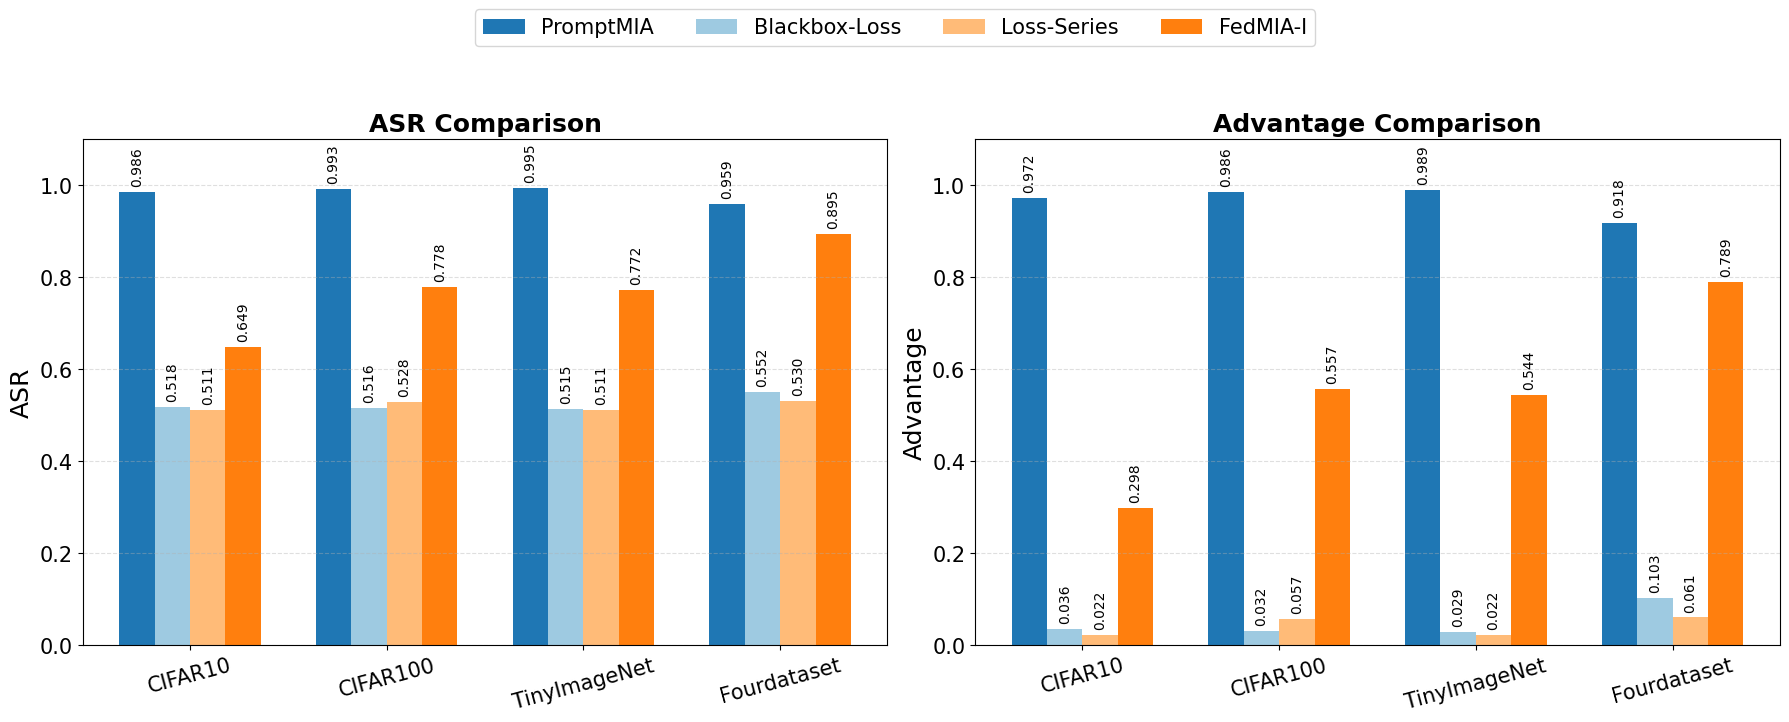

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

promptmia_results = {
    "CIFAR10": {"ASR": 0.9858, "TPR": 0.9717},
    "CIFAR100": {"ASR": 0.9931, "TPR": 0.9861},
    "TinyImageNet": {"ASR": 0.9945, "TPR": 0.9891},
    "Fourdataset": {"ASR": 0.9592, "TPR": 0.9184},
}

best_attack_results = {
    "CIFAR10": {
        "Blackbox-Loss": {"ASR": 0.5178, "Adv": 0.0356},
        "Loss-Series": {"ASR": 0.5112, "Adv": 0.0224},
        "FedMIA-I": {"ASR": 0.6490, "Adv": 0.2980},
    },
    "CIFAR100": {
        "Blackbox-Loss": {"ASR": 0.5158, "Adv": 0.0316},
        "Loss-Series": {"ASR": 0.5284, "Adv": 0.0569},
        "FedMIA-I": {"ASR": 0.7785, "Adv": 0.5571},
    },
    "TinyImageNet": {
        "Blackbox-Loss": {"ASR": 0.5146, "Adv": 0.0292},
        "Loss-Series": {"ASR": 0.5112, "Adv": 0.0225},
        "FedMIA-I": {"ASR": 0.7722, "Adv": 0.5444},
    },
    "Fourdataset": {
        "Blackbox-Loss": {"ASR": 0.5517, "Adv": 0.1035},
        "Loss-Series": {"ASR": 0.5303, "Adv": 0.0607},
        "FedMIA-I": {"ASR": 0.8946, "Adv": 0.7892},
    },
}

method_order = [
    "PromptMIA",
    "Blackbox-Loss",
    "Loss-Series",
    "FedMIA-I",
]
datasets = ["CIFAR10", "CIFAR100", "TinyImageNet", "Fourdataset"]

comparison_rows = []
for dataset in datasets:
    promptmia_adv = 2 * promptmia_results[dataset]["ASR"] - 1
    comparison_rows.append(
        {
            "Dataset": dataset,
            "Method": "PromptMIA",
            "ASR": promptmia_results[dataset]["ASR"],
            "Adv": promptmia_adv,
        }
    )
    for method, values in best_attack_results[dataset].items():
        comparison_rows.append(
            {
                "Dataset": dataset,
                "Method": method,
                "ASR": values["ASR"],
                "Adv": values["Adv"],
            }
        )

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

method_colors = {
    "PromptMIA": "#1f77b4",
    "Blackbox-Loss": "#9ecae1",
    "Loss-Series": "#ffbb78",
    "FedMIA-I": "#ff7f0e",
}

title_size = 20
axis_title_size = 18
tick_size = 15
legend_size = 15
value_size = 10

x = np.arange(len(datasets))
width = 0.18
offsets = np.linspace(-1.5, 1.5, len(method_order)) * width

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharex=True)

for idx, method in enumerate(method_order):
    subset = comparison_df[comparison_df["Method"] == method].set_index("Dataset").loc[datasets]
    bars_asr = axes[0].bar(
        x + offsets[idx],
        subset["ASR"],
        width,
        label=method,
        color=method_colors[method],
    )
    bars_adv = axes[1].bar(
        x + offsets[idx],
        subset["Adv"],
        width,
        label=method,
        color=method_colors[method],
    )

    for bar in bars_asr:
        height = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=value_size,
            rotation=90,
        )
    for bar in bars_adv:
        height = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=value_size,
            rotation=90,
        )

axes[0].set_title("ASR Comparison", fontsize=axis_title_size, weight="bold")
axes[0].set_ylabel("ASR", fontsize=axis_title_size)
axes[0].set_xticks(x)
axes[0].set_xticklabels(datasets, rotation=15, fontsize=tick_size)
axes[0].tick_params(axis="y", labelsize=tick_size)
axes[0].set_ylim(0, 1.1)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

axes[1].set_title("Advantage Comparison", fontsize=axis_title_size, weight="bold")
axes[1].set_ylabel("Advantage", fontsize=axis_title_size)
axes[1].set_xticks(x)
axes[1].set_xticklabels(datasets, rotation=15, fontsize=tick_size)
axes[1].tick_params(axis="y", labelsize=tick_size)
axes[1].set_ylim(0, 1.1)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=True, bbox_to_anchor=(0.5, 1.04), fontsize=legend_size)
# fig.suptitle("PromptMIA vs Best Results of All Attacks", fontsize=title_size, weight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()
